# 03 — Özellikler v2

v1'de bulunan sorunlar ve yapılan güncellemeler (ayrıntı: `UPDATES.md`):

| # | Sorun (v1) | Güncelleme (v2) |
|---|---|---|
| 1 | Model ayakta kalan Pokémon'ların **gücünü** ve **tipleri** görmüyordu | `alive_strength`, `super_eff_hits`, `resisted_hits`, `active_type_adv`, `active_spe`, `active_threat`, `max_boost_sum` |
| 2 | `damage_dealt` switch turlarındaki ve 1. turdaki hasarı kaçırıyordu, iyileşmeyi saymıyordu | `damage_taken` + `healed` (her Pokémon'un canı ayrı takip ediliyor) |
| 3 | Seyrek sütunlar (`n_frz` %1.4, `n_brn`, `boost_spd` %0.7) | `n_disabled` = slp+frz, `n_poisoned` = tox+psn, `boost_spd` atıldı |
| 4 | Mükemmel multicollinearity (rank 40/49) | `select_features(X, "linear")` / `"tree"` — model ailesine göre sütun seti |
| 5 | Tek 5-fold CV gürültülü (±0.006) | `src/validation.py`: 5-fold × 3 tekrar |

**Not:** P2'nin görülen Pokémon'larının stat/tipi verilmiyor → competition verisindeki P1 takımlarından ve P2 lead'lerinden bir **tür tablosu** derleniyor (`load_species`). Etiket kullanılmıyor, dış veri yok.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import features_v1
from src.features_v2 import load_species, load_type_chart, build_features, select_features
from src.validation import cv_accuracy

train = pd.read_json("data/train.jsonl", lines=True)
test = pd.read_json("data/test.jsonl", lines=True)

species = load_species([train, test])
chart = load_type_chart("data/type_chart_gen2.csv")

X = build_features(train, species, chart)
y = train.set_index("battle_id").loc[X.index, "player_won"]
X_test = build_features(test, species, chart)
X_v1 = features_v1.build_features(train)

print("tür tablosu:", len(species), "Pokémon")
print("v1:", X_v1.shape, " v2:", X.shape)

tür tablosu: 247 Pokémon
v1: (10000, 49)  v2: (10000, 70)


## 1. Yeni özellikler savaş 0'da

Hatırlatma: 30. turda sahada P1 **Typhlosion** (fire), P2 **Forretress** (bug/steel).

In [2]:
new_cols = ["p1_alive_strength", "p2_alive_strength", "p1_damage_taken", "p2_damage_taken",
            "p1_healed", "p2_healed", "p1_super_eff_hits", "p2_super_eff_hits",
            "p1_max_boost_sum", "p2_max_boost_sum", "active_type_adv"]
X.loc[0, new_cols].round(3).to_frame("savaş 0")

,savaş 0
p1_alive_strength,4.093
p2_alive_strength,3.888
p1_damage_taken,3.510
p2_damage_taken,2.160
p1_healed,2.190
p2_healed,1.830
p1_super_eff_hits,0.000
p2_super_eff_hits,2.000
p1_max_boost_sum,2.000
p2_max_boost_sum,3.000


- `active_type_adv = 3.5` → fire, bug/steel'e **4×** vuruyor (bug 2× · steel 2×); Forretress'in tipleri fire'a **0.5×**. Fark: 4 − 0.5 = 3.5 → P1'in sahadaki eşleşmesi çok iyi.
- `p2_max_boost_sum = 3` → P2'nin Snorlax'ı savaş boyunca +3 Curse'e ulaştı.
- `p1_damage_taken` (3.51) > `p2_damage_taken` (2.16) → P1 daha çok hasar yedi.

## 2. Multicollinearity kontrolü

In [3]:
for kind in ["linear", "tree"]:
    XX = select_features(X, kind).values.astype(float)
    print(f"{kind:6s}: {XX.shape[1]} sütun, rank {np.linalg.matrix_rank(XX)}")

linear: 53 sütun, rank 53
tree  : 70 sütun, rank 54


`linear` set tam rank → Logistic Regression katsayıları artık yorumlanabilir. `tree` set bilerek tekrar içeriyor (farklar ağaçlara yardım ediyor).

## 3. v1 vs v2 (5-fold × 3 tekrar)

In [4]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

def models():
    return {
        "LogisticRegression": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), "linear"),
        "RandomForest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42), "tree"),
        "HistGradientBoosting": (HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_leaf_nodes=15, random_state=42), "tree"),
    }

rows = []
for name, (model, kind) in models().items():
    m1, s1 = cv_accuracy(model, X_v1, y)
    m2, s2 = cv_accuracy(model, select_features(X, kind), y)
    rows.append({"model": name, "v1": m1, "v1_std": s1, "v2": m2, "v2_std": s2, "fark": m2 - m1})
comparison = pd.DataFrame(rows).set_index("model").round(4)
comparison

,v1,v1_std,v2,v2_std,fark
model,,,,,
LogisticRegression,0.6682,0.0048,0.6681,0.0056,-0.0001
RandomForest,0.6677,0.0069,0.6658,0.0066,-0.0019
HistGradientBoosting,0.6668,0.0064,0.6675,0.0070,0.0007


## 4. Ablation: her yeni grup kaç puan getiriyor?
v2'den bir grubu çıkarıp skora bakıyoruz. **Skor düşüyorsa grup işe yarıyor.** (LR ve HistGB ile — RF bu döngü için yavaş.)

In [5]:
groups = {
    "alive_strength": ["alive_strength"],
    "hasar/iyileşme": ["damage_taken", "healed", "diff_damage"],
    "tip": ["super_eff", "resisted", "type_adv"],
    "sahadaki ekstra": ["active_threat", "active_spe", "active_total"],
    "max_boost": ["max_boost"],
    "hp_seen_mean": ["hp_seen_mean"],
}

base = {name: cv_accuracy(m, select_features(X, kind), y)[0]
        for name, (m, kind) in models().items() if name != "RandomForest"}

rows = []
for g, pats in groups.items():
    Xg = X.drop(columns=[c for c in X.columns if any(p in c for p in pats)])
    row = {"grup çıkarılınca": g}
    for name, (m, kind) in models().items():
        if name == "RandomForest":
            continue
        row[name] = cv_accuracy(m, select_features(Xg, kind), y)[0] - base[name]
    rows.append(row)
ablation = pd.DataFrame(rows).set_index("grup çıkarılınca").round(4)
print("v2 tam set:", {k: round(v, 4) for k, v in base.items()})
ablation

v2 tam set: {'LogisticRegression': np.float64(0.6681), 'HistGradientBoosting': np.float64(0.6675)}


,LogisticRegression,HistGradientBoosting
grup çıkarılınca,,
alive_strength,0.0013,-0.0013
hasar/iyileşme,0.0005,-0.0007
tip,-0.0022,-0.0010
sahadaki ekstra,0.0001,-0.0025
max_boost,-0.0015,-0.0004
hp_seen_mean,0.0006,-0.0017


## 5. Logistic Regression katsayıları (v2, tam rank)

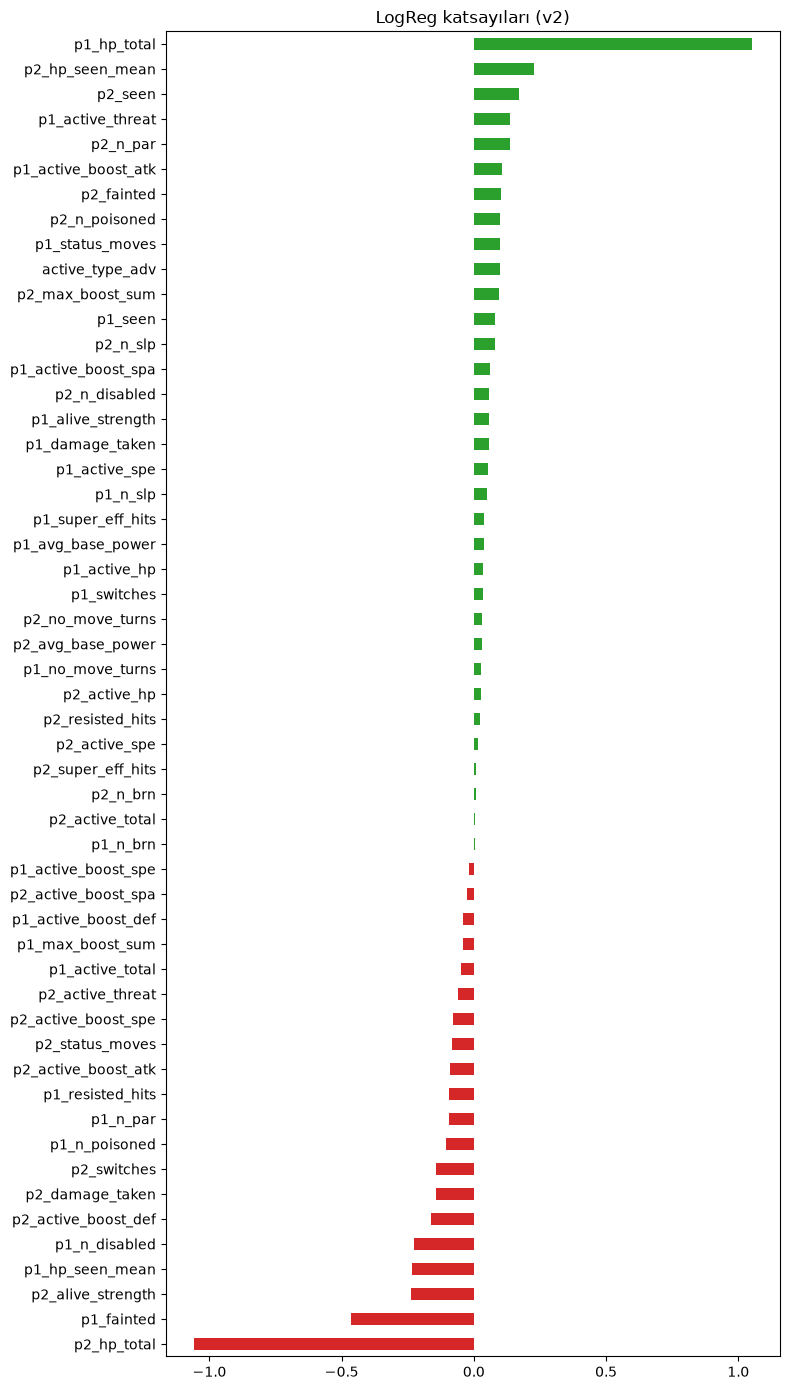

In [6]:
Xl = select_features(X, "linear")
lr = models()["LogisticRegression"][0].fit(Xl, y)
coef = pd.Series(lr[-1].coef_[0], index=Xl.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 14))
coef.plot.barh(ax=ax, color=np.where(coef > 0, "tab:green", "tab:red"))
ax.set_title("LogReg katsayıları (v2)"); plt.tight_layout(); plt.show()

## 6. Submission (v2)

In [7]:
best_name = comparison["v2"].idxmax()
model, kind = models()[best_name]
model.fit(select_features(X, kind), y)
pred = model.predict(select_features(X_test, kind)).astype(int)
sub = pd.DataFrame({"battle_id": X_test.index, "player_won": pred})
sub.to_csv("submission_v2.csv", index=False)
print("Model:", best_name, " CV:", comparison.loc[best_name, "v2"])
sub.player_won.value_counts(normalize=True)

Model: LogisticRegression  CV: 0.6681


player_won
1    0.5152
0    0.4848
Name: proportion, dtype: float64